In [ ]:
from ultralytics import YOLO

# The 'results' object from the previous training run contains the path to the best model.
# However, it's safer to explicitly load the best.pt from the last training run directory.
# Based on the previous output, the training run directory was: /content/runs/detect/train_pcb_yolov8n_v22
best_model_path = '/content/runs/detect/train_pcb_yolov8n_v22/weights/best.pt'

# Load the best trained model
model = YOLO(best_model_path)

# Evaluate the model on the test dataset
# The 'split="test"' argument ensures evaluation is done on the test set defined in data.yaml
metrics = model.val(
    data='data.yaml',
    split='test', # Explicitly specify the test split
    imgsz=640,
    project='runs/detect',
    name='eval_pcb_yolov8n_v2_test' # Name for the evaluation run
)

print("Model evaluation initiated.")

# Print key metrics
print("--- Evaluation Metrics ---")
print(f"Map50: {metrics.box.map50}")
print(f"Map: {metrics.box.map}") # mAP@.5:.95
print(f"Precision: {metrics.box.p}")
print(f"Recall: {metrics.box.r}")

## Evaluate the Trained YOLOv8-Nano Model

### Subtask:
Evaluate the performance of the trained YOLOv8-Nano model on the test dataset. This includes loading the best-trained model, performing inference on the test set, and analyzing the results, potentially through metrics or visualizations.

In [ ]:
import os

# Recursively list contents of PROPER_PCBs
print('Contents of PROPER_PCBs directory:')
for root, dirs, files in os.walk('PROPER_PCBs'):
    level = root.replace('PROPER_PCBs', '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        print(f'{subindent}{f}')

print('\nContents of PCBData directory:')
for root, dirs, files in os.walk('PCBData'):
    level = root.replace('PCBData', '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        print(f'{subindent}{f}')

Contents of PROPER_PCBs directory:
PROPER_PCBs/
    PROPER PCBs/
        SIX.jpg
        THREE.jpg
        EIGHT.jpg
        FOUR.jpg
        FIVE.jpg
        TWO.jpg
        ONE.avif
        SEVEN.jpg
        Template-PCB-images/
            11.JPG
            01_left.JPG
            05.JPG
            05_right.JPG
            07_right.JPG
            05_180.JPG
            01_180.JPG
            10_right.JPG
            01_right.JPG
            07_180.JPG
            01.JPG
            11_left.JPG
            10_180.JPG
            README.md
            05_left.JPG
            07_left.JPG
            10.JPG
            07.JPG
            10_left.JPG
            11_right.JPG
            11_180.JPG

Contents of PCBData directory:
PCBData/
    PCBData/
        test.txt
        trainval.txt
        group50600/
            50600_not/
                50600006.txt
                50600068.txt
                50600044.txt
                50600028.txt
                50600055.txt
            

In [ ]:
import zipfile
import os

# Unzip 'PROPER PCBs.zip'
with zipfile.ZipFile('PROPER PCBs.zip', 'r') as zip_ref:
    zip_ref.extractall('PROPER_PCBs')

# Unzip 'PCBData.zip'
with zipfile.ZipFile('PCBData.zip', 'r') as zip_ref:
    zip_ref.extractall('PCBData')

print('Dataset files unzipped successfully.')
print('Contents of PROPER_PCBs:')
print(os.listdir('PROPER_PCBs'))
print('\nContents of PCBData:')
print(os.listdir('PCBData'))

Dataset files unzipped successfully.
Contents of PROPER_PCBs:
['PROPER PCBs']

Contents of PCBData:
['PCBData']


Next, we'll install `ultralytics`, the library that provides the YOLOv8 model. We'll also install `matplotlib` and `seaborn` for visualization, and `ipywidgets` for interactive elements if needed.

In [ ]:
!pip install ultralytics matplotlib seaborn ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 52.3 MB/s eta 0:00:00


# Task
To prepare the dataset for YOLOv8, I'll first gather all image and annotation file paths, analyze the `trainval.txt` and `test.txt` splits, and then determine the unique class IDs from the annotation files. I'll then organize the dataset into the YOLOv8-compatible structure and generate the `data.yaml` configuration file.

## Analyze Dataset Structure

### Subtask:
Gather all image and annotation file paths, analyze the `trainval.txt` and `test.txt` splits, and determine the unique class IDs from the annotation files.


**Reasoning**:
The first step is to set up the necessary file paths and define a helper function to load the base names from the train/validation and test split files. This function will read the content of these files, clean the names, and return a set of unique base names for further processing.



In [ ]:
import os

# 1. Define file paths
trainval_file = 'PCBData/PCBData/trainval.txt'
test_file = 'PCBData/PCBData/test.txt'
data_root_dir = 'PCBData/PCBData'

# 2. Create a helper function, load_split_names(file_path)
def load_split_names(file_path):
    """Reads a text file, extracts each line as a base name, and returns a set of unique base names."""
    base_names = set()
    with open(file_path, 'r') as f:
        for line in f:
            # Strip whitespace and any file extensions/suffixes to get the base name
            name = line.strip()
            # Remove _temp.jpg, _test.jpg, .jpg, .txt if present to get the pure base name (e.g., '50600022')
            if name.endswith('_temp.jpg'):
                name = name[:-9] # Remove '_temp.jpg'
            elif name.endswith('_test.jpg'):
                name = name[:-9] # Remove '_test.jpg'
            elif name.endswith('.jpg'):
                name = name[:-4] # Remove '.jpg'
            elif name.endswith('.txt'):
                name = name[:-4] # Remove '.txt'

            base_names.add(name)
    return base_names

# 3. Use the load_split_names function to load the base names
train_val_base_names = load_split_names(trainval_file)
test_base_names = load_split_names(test_file)

print(f"Loaded {len(train_val_base_names)} training/validation base names.")
print(f"Loaded {len(test_base_names)} test base names.")

# 4. Initialize an empty dictionary, dataset_map
dataset_map = {}

# 5. Initialize an empty set, unique_class_ids
unique_class_ids = set()

Loaded 1000 training/validation base names.
Loaded 500 test base names.


**Reasoning**:
Now that the base names for train/validation and test sets are loaded, and initial data structures are prepared, the next step is to recursively walk through the data directories to populate the `dataset_map` with image and annotation file paths and extract unique class IDs from the annotation files, as outlined in the instructions.



In [ ]:
import os

# 6. Walk through the PCBData/PCBData/group* directories recursively
for root, dirs, files in os.walk(data_root_dir):
    for file in files:
        full_path = os.path.join(root, file)
        base_name = ''

        # Process image files
        if file.endswith(('.jpg', '.jpeg', '.png', '.avif')):
            if file.endswith('_temp.jpg'):
                base_name = file[:-9] # Remove '_temp.jpg'
            elif file.endswith('_test.jpg'):
                base_name = file[:-9] # Remove '_test.jpg'
            elif file.endswith('.jpg'):
                base_name = file[:-4] # Remove '.jpg'
            elif file.endswith('.jpeg'):
                base_name = file[:-5] # Remove '.jpeg'
            elif file.endswith('.png'):
                base_name = file[:-4] # Remove '.png'
            elif file.endswith('.avif'):
                base_name = file[:-5] # Remove '.avif'

            if base_name:
                if base_name not in dataset_map:
                    dataset_map[base_name] = {'image': None, 'label': None}
                dataset_map[base_name]['image'] = full_path

        # Process annotation files
        elif file.endswith('.txt') and '_not' in root:
            base_name = file[:-4] # Remove '.txt'
            if base_name:
                if base_name not in dataset_map:
                    dataset_map[base_name] = {'image': None, 'label': None}
                dataset_map[base_name]['label'] = full_path

                # Extract unique class IDs
                try:
                    with open(full_path, 'r') as f_label:
                        for line in f_label:
                            parts = line.strip().split()
                            if parts:
                                class_id = int(parts[0])
                                unique_class_ids.add(class_id)
                except Exception as e:
                    print(f"Error reading annotation file {full_path}: {e}")

print(f"Populated dataset_map with {len(dataset_map)} entries.")
print(f"Found {len(unique_class_ids)} unique class IDs.")

Populated dataset_map with 1501 entries.
Found 618 unique class IDs.


**Reasoning**:
With `dataset_map` populated and `train_val_base_names` and `test_base_names` loaded, the next step is to create separate dictionaries for the training/validation and test sets, ensuring both image and label paths exist for each entry, and then print a comprehensive summary of the dataset analysis.



In [ ]:
import os

# 7. Create two new dictionaries, train_val_dataset_map and test_dataset_map
train_val_dataset_map = {}
test_dataset_map = {}

for base_name, paths in dataset_map.items():
    if paths['image'] and paths['label']:
        if base_name in train_val_base_names:
            train_val_dataset_map[base_name] = paths
        elif base_name in test_base_names:
            test_dataset_map[base_name] = paths

# 8. Print a summary of the analysis
print(f"\n--- Dataset Analysis Summary ---")
print(f"Total unique base names processed: {len(dataset_map)}")
print(f"Number of training/validation entries with both image and label: {len(train_val_dataset_map)}")
print(f"Number of test entries with both image and label: {len(test_dataset_map)}")
print(f"Total unique class IDs found: {len(unique_class_ids)}")
print(f"Unique class IDs: {sorted(list(unique_class_ids))}")



--- Dataset Analysis Summary ---
Total unique base names processed: 1501
Number of training/validation entries with both image and label: 0
Number of test entries with both image and label: 0
Total unique class IDs found: 618
Unique class IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172,

**Reasoning**:
The previous execution indicated that the `train_val_dataset_map` and `test_dataset_map` were empty, suggesting a mismatch in how base names were derived from the split files (`trainval.txt`, `test.txt`) and the actual data files. The `load_split_names` helper function needs to be updated to correctly extract the base name by first using `os.path.basename` to handle potential directory paths in the split files, and then stripping suffixes. I will re-execute the entire dataset analysis from defining file paths to printing the summary with this corrected logic to resolve the issue.



In [ ]:
import os

# 1. Define file paths
trainval_file = 'PCBData/PCBData/trainval.txt'
test_file = 'PCBData/PCBData/test.txt'
data_root_dir = 'PCBData/PCBData'

# 2. Create a helper function, load_split_names(file_path)
def load_split_names(file_path):
    """Reads a text file, extracts each line as a base name, and returns a set of unique base names."""
    base_names = set()
    with open(file_path, 'r') as f:
        for line in f:
            name = line.strip()
            # First, get the filename from the path if it's a path
            name = os.path.basename(name)

            # Then, remove _temp.jpg, _test.jpg, .jpg, .txt if present to get the pure base name (e.g., '50600022')
            if name.endswith('_temp.jpg'):
                name = name[:-9] # Remove '_temp.jpg'
            elif name.endswith('_test.jpg'):
                name = name[:-9] # Remove '_test.jpg'
            elif name.endswith('.jpg'):
                name = name[:-4] # Remove '.jpg'
            elif name.endswith('.jpeg'):
                name = name[:-5] # Remove '.jpeg'
            elif name.endswith('.png'):
                name = name[:-4] # Remove '.png'
            elif name.endswith('.avif'):
                name = name[:-5] # Remove '.avif'
            elif name.endswith('.txt'):
                name = name[:-4] # Remove '.txt'

            base_names.add(name)
    return base_names

# 3. Use the load_split_names function to load the base names
train_val_base_names = load_split_names(trainval_file)
test_base_names = load_split_names(test_file)

print(f"Loaded {len(train_val_base_names)} training/validation base names.")
print(f"Loaded {len(test_base_names)} test base names.")

# 4. Initialize an empty dictionary, dataset_map
dataset_map = {}

# 5. Initialize an empty set, unique_class_ids
unique_class_ids = set()

# 6. Walk through the PCBData/PCBData/group* directories recursively
for root, dirs, files in os.walk(data_root_dir):
    for file in files:
        full_path = os.path.join(root, file)
        base_name = ''

        # Process image files
        if file.endswith(('.jpg', '.jpeg', '.png', '.avif')):
            if file.endswith('_temp.jpg'):
                base_name = file[:-9] # Remove '_temp.jpg'
            elif file.endswith('_test.jpg'):
                base_name = file[:-9] # Remove '_test.jpg'
            elif file.endswith('.jpg'):
                base_name = file[:-4] # Remove '.jpg'
            elif file.endswith('.jpeg'):
                base_name = file[:-5] # Remove '.jpeg'
            elif file.endswith('.png'):
                base_name = file[:-4] # Remove '.png'
            elif file.endswith('.avif'):
                base_name = file[:-5] # Remove '.avif'

            if base_name:
                if base_name not in dataset_map:
                    dataset_map[base_name] = {'image': None, 'label': None}
                dataset_map[base_name]['image'] = full_path

        # Process annotation files
        elif file.endswith('.txt') and '_not' in root:
            base_name = file[:-4] # Remove '.txt'
            if base_name:
                if base_name not in dataset_map:
                    dataset_map[base_name] = {'image': None, 'label': None}
                dataset_map[base_name]['label'] = full_path

                # Extract unique class IDs
                try:
                    with open(full_path, 'r') as f_label:
                        for line_label in f_label:
                            parts = line_label.strip().split()
                            if parts:
                                class_id = int(parts[0])
                                unique_class_ids.add(class_id)
                except Exception as e:
                    print(f"Error reading annotation file {full_path}: {e}")

print(f"Populated dataset_map with {len(dataset_map)} entries.")
print(f"Found {len(unique_class_ids)} unique class IDs.")

# 7. Create two new dictionaries, train_val_dataset_map and test_dataset_map
train_val_dataset_map = {}
test_dataset_map = {}

for base_name, paths in dataset_map.items():
    if paths['image'] and paths['label']:
        if base_name in train_val_base_names:
            train_val_dataset_map[base_name] = paths
        elif base_name in test_base_names:
            test_dataset_map[base_name] = paths

# 8. Print a summary of the analysis
print(f"\n--- Dataset Analysis Summary ---")
print(f"Total unique base names processed: {len(dataset_map)}")
print(f"Number of training/validation entries with both image and label: {len(train_val_dataset_map)}")
print(f"Number of test entries with both image and label: {len(test_dataset_map)}")
print(f"Total unique class IDs found: {len(unique_class_ids)}")
print(f"Unique class IDs: {sorted(list(unique_class_ids))}")

Loaded 1000 training/validation base names.
Loaded 500 test base names.
Populated dataset_map with 1501 entries.
Found 618 unique class IDs.

--- Dataset Analysis Summary ---
Total unique base names processed: 1501
Number of training/validation entries with both image and label: 1000
Number of test entries with both image and label: 500
Total unique class IDs found: 618
Unique class IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143

## Create YOLOv8 Data Configuration File

### Subtask:
Generate a `data.yaml` file specifying the paths for training, validation, and test datasets, along with the number of classes and class names, suitable for YOLOv8.


**Reasoning**:
The first step is to determine the total number of classes (`nc`) and generate the corresponding class names list (`names`) based on the `unique_class_ids` found in the previous analysis. This information is crucial for the `data.yaml` file.



In [ ]:
import yaml

# 1. Determine the total number of classes (nc)
# Find the maximum class ID from unique_class_ids and add 1
if unique_class_ids:
    nc = max(unique_class_ids) + 1
else:
    nc = 0 # No classes found

# 2. Generate a list of class names (names)
names = [f'class_{i}' for i in range(nc)]

print(f"Number of classes (nc): {nc}")
print(f"Generated class names (first 5): {names[:5]}...")

Number of classes (nc): 622
Generated class names (first 5): ['class_0', 'class_1', 'class_2', 'class_3', 'class_4']...


**Reasoning**:
Now that the number of classes and class names have been determined, I will define the YOLOv8 dataset structure's root and relative paths for images and labels, create a dictionary with all the necessary configuration, and then write it to a `data.yaml` file.



In [ ]:
import os
import yaml

# 3. Define the root directory for the YOLOv8 dataset structure
yolov8_dataset_root = 'yolov8_dataset'

# 4. Specify the relative paths for the training, validation, and test image and label directories
# YOLOv8 expects a specific directory structure for training, validation, and test images and labels.
# We will use 'images' and 'labels' subdirectories within 'train', 'val', and 'test'.

train_images_path = os.path.join(yolov8_dataset_root, 'train', 'images')
train_labels_path = os.path.join(yolov8_dataset_root, 'train', 'labels')
val_images_path = os.path.join(yolov8_dataset_root, 'val', 'images')
val_labels_path = os.path.join(yolov8_dataset_root, 'val', 'labels')
test_images_path = os.path.join(yolov8_dataset_root, 'test', 'images')
test_labels_path = os.path.join(yolov8_dataset_root, 'test', 'labels')

# 5. Create a Python dictionary containing the path, train, val, test, nc, and names entries
data_yaml_content = {
    'path': os.path.abspath(yolov8_dataset_root), # Dataset root directory
    'train': 'train/images', # Train images relative path to 'path'
    'val': 'val/images', # Val images relative path to 'path'
    'test': 'test/images', # Test images relative path to 'path'
    'nc': nc, # Number of classes
    'names': names # Class names
}

# 6. Use yaml.dump() to write this dictionary to a file named data.yaml
data_yaml_path = 'data.yaml'
with open(data_yaml_path, 'w') as f:
    yaml.dump(data_yaml_content, f, default_flow_style=False)

print(f"Generated data.yaml at {data_yaml_path} with the following content:")
print(yaml.dump(data_yaml_content, default_flow_style=False))


Generated data.yaml at data.yaml with the following content:
names:
- class_0
- class_1
- class_2
- class_3
- class_4
- class_5
- class_6
- class_7
- class_8
- class_9
- class_10
- class_11
- class_12
- class_13
- class_14
- class_15
- class_16
- class_17
- class_18
- class_19
- class_20
- class_21
- class_22
- class_23
- class_24
- class_25
- class_26
- class_27
- class_28
- class_29
- class_30
- class_31
- class_32
- class_33
- class_34
- class_35
- class_36
- class_37
- class_38
- class_39
- class_40
- class_41
- class_42
- class_43
- class_44
- class_45
- class_46
- class_47
- class_48
- class_49
- class_50
- class_51
- class_52
- class_53
- class_54
- class_55
- class_56
- class_57
- class_58
- class_59
- class_60
- class_61
- class_62
- class_63
- class_64
- class_65
- class_66
- class_67
- class_68
- class_69
- class_70
- class_71
- class_72
- class_73
- class_74
- class_75
- class_76
- class_77
- class_78
- class_79
- class_80
- class_81
- class_82
- class_83
- class_84
- class

## Prepare Dataset for YOLOv8 Training

### Subtask:
Organize the image and label files into the directory structure expected by YOLOv8 (e.g., dataset/images/train, dataset/labels/train, etc.), potentially involving moving or symlinking files based on the `test.txt` and `trainval.txt` splits.


**Reasoning**:
The next step is to create the required directory structure for YOLOv8, define a helper function to copy the image and label files from the processed dataset maps, and then execute this function for both the training/validation and test datasets.



In [ ]:
import os
import shutil

# 1. Create the base directory for the YOLOv8 dataset structure
os.makedirs(yolov8_dataset_root, exist_ok=True)

# 2. Create the subdirectories within the yolov8_dataset_root
os.makedirs(train_images_path, exist_ok=True)
os.makedirs(train_labels_path, exist_ok=True)
os.makedirs(val_images_path, exist_ok=True)
os.makedirs(val_labels_path, exist_ok=True)
os.makedirs(test_images_path, exist_ok=True)
os.makedirs(test_labels_path, exist_ok=True)

print(f"Created YOLOv8 dataset directory structure under '{yolov8_dataset_root}'.")

# 3. Define a helper function, copy_files_to_yolov8_structure
def copy_files_to_yolov8_structure(dataset_map, image_dest_dir, label_dest_dir):
    """Copies image and label files to the YOLOv8-compatible directory structure."""
    copied_count = 0
    for base_name, paths in dataset_map.items():
        if paths['image'] and paths['label']:
            try:
                # Determine new file names with .jpg and .txt extensions
                image_extension = os.path.splitext(paths['image'])[1]
                new_image_name = f"{base_name}{image_extension}"
                new_label_name = f"{base_name}.txt"

                # Copy image file
                shutil.copy(paths['image'], os.path.join(image_dest_dir, new_image_name))

                # Copy label file
                shutil.copy(paths['label'], os.path.join(label_dest_dir, new_label_name))
                copied_count += 1
            except Exception as e:
                print(f"Error copying files for {base_name}: {e}")
    return copied_count

# 4. Call the copy_files_to_yolov8_structure function
# For training/validation set
train_val_copied_count = copy_files_to_yolov8_structure(train_val_dataset_map, train_images_path, train_labels_path)

# For test set
test_copied_count = copy_files_to_yolov8_structure(test_dataset_map, test_images_path, test_labels_path)

# 5. Print a confirmation message
print(f"\n--- File Copy Summary ---")
print(f"Copied {train_val_copied_count} image/label pairs to training/validation directories.")
print(f"Copied {test_copied_count} image/label pairs to test directories.")

Created YOLOv8 dataset directory structure under 'yolov8_dataset'.

--- File Copy Summary ---
Copied 1000 image/label pairs to training/validation directories.
Copied 500 image/label pairs to test directories.


## Visualize Sample Images with Annotations

### Subtask:
Display a few sample images with their bounding box annotations overlaid to verify that the dataset preparation and configuration are correct before training.


**Reasoning**:
I need to import the necessary libraries (`os`, `cv2`, `matplotlib.pyplot`), define the `plot_annotations` function to load an image, parse its YOLO annotations, draw bounding boxes and class labels, and then select a few sample images from the training set to display with their annotations.



In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

# 2. Define a function, plot_annotations
def plot_annotations(image_path, label_path, class_names):
    """Displays an image with its YOLO bounding box annotations overlaid."""
    # 3a. Load the image and convert to RGB
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: Could not load image {image_path}")
        return
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Get image dimensions
    h, w, _ = img.shape

    # 3c. Read the annotation file
    try:
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    class_id = int(parts[0])
                    center_x, center_y, bbox_width, bbox_height = map(float, parts[1:])

                    # 3d. Convert normalized coordinates to absolute pixel coordinates
                    x_center = int(center_x * w)
                    y_center = int(y_center * h)
                    box_w = int(bbox_width * w)
                    box_h = int(bbox_height * h)

                    x_min = int(x_center - box_w / 2)
                    y_min = int(y_center - box_h / 2)
                    x_max = int(x_center + box_w / 2)
                    y_max = int(y_center + box_h / 2)

                    # 3e. Draw the bounding box and add the class label
                    color = (0, 255, 0) # Green color for bounding box
                    cv2.rectangle(img, (x_min, y_min), (x_max, y_max), color, 2)

                    label = class_names[class_id] if class_id < len(class_names) else f'class_{class_id}'
                    font = cv2.FONT_HERSHEY_SIMPLEX
                    font_scale = 0.7
                    font_thickness = 2
                    text_size = cv2.getTextSize(label, font, font_scale, font_thickness)[0]
                    text_x = x_min
                    text_y = y_min - 10 if y_min - 10 > 10 else y_min + text_size[1] + 10 # Adjust text position
                    cv2.putText(img, label, (text_x, text_y), font, font_scale, color, font_thickness, cv2.LINE_AA)

    except FileNotFoundError:
        print(f"Error: Label file not found at {label_path}")
        return
    except Exception as e:
        print(f"Error processing annotations for {label_path}: {e}")
        return

    # 3f. Display the image with annotations
    plt.figure(figsize=(10, 10))
    plt.imshow(img)
    plt.title(os.path.basename(image_path))
    plt.axis('off')
    plt.show()

# 4. Select a few sample image and label file pairs from train_val_dataset_map
sample_count = 3
sample_base_names = list(train_val_dataset_map.keys())[:sample_count]

print(f"Displaying {sample_count} sample images with annotations from the training/validation set:")
for base_name in sample_base_names:
    image_original_path = train_val_dataset_map[base_name]['image']
    label_original_path = train_val_dataset_map[base_name]['label']

    # Construct the path to the copied files in the YOLOv8 structure
    image_name = os.path.basename(image_original_path)
    label_name = os.path.basename(label_original_path)

    yolov8_image_path = os.path.join(train_images_path, image_name)
    yolov8_label_path = os.path.join(train_labels_path, label_name)

    plot_annotations(yolov8_image_path, yolov8_label_path, names)

Displaying 3 sample images with annotations from the training/validation set:
Error: Could not load image yolov8_dataset/train/images/50600006_test.jpg
Error: Could not load image yolov8_dataset/train/images/50600044_test.jpg
Error: Could not load image yolov8_dataset/train/images/50600028_test.jpg


**Reasoning**:
The previous attempt to display images failed because the constructed paths to the copied YOLOv8 images were incorrect. The image files were copied using a base name (e.g., '50600006') and their original extension (e.g., '.jpg'), but the visualization code was still trying to append suffixes like '_test.jpg' or '_temp.jpg'. I need to correct the construction of `yolov8_image_path` and `yolov8_label_path` to match how the files were actually named and copied into the `yolov8_dataset` structure, specifically using the `base_name` derived from the `dataset_map` keys and the correct file extensions.



In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

# 2. Define a function, plot_annotations
def plot_annotations(image_path, label_path, class_names):
    """Displays an image with its YOLO bounding box annotations overlaid."""
    # 3a. Load the image and convert to RGB
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: Could not load image {image_path}")
        return
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Get image dimensions
    h, w, _ = img.shape

    # 3c. Read the annotation file
    try:
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    class_id = int(parts[0])
                    center_x, center_y, bbox_width, bbox_height = map(float, parts[1:])

                    # 3d. Convert normalized coordinates to absolute pixel coordinates
                    x_center = int(center_x * w)
                    y_center = int(y_center * h)
                    box_w = int(bbox_width * w)
                    box_h = int(bbox_height * h)

                    x_min = int(x_center - box_w / 2)
                    y_min = int(y_center - box_h / 2)
                    x_max = int(x_center + box_w / 2)
                    y_max = int(y_center + box_h / 2)

                    # 3e. Draw the bounding box and add the class label
                    color = (0, 255, 0) # Green color for bounding box
                    cv2.rectangle(img, (x_min, y_min), (x_max, y_max), color, 2)

                    label = class_names[class_id] if class_id < len(class_names) else f'class_{class_id}'
                    font = cv2.FONT_HERSHEY_SIMPLEX
                    font_scale = 0.7
                    font_thickness = 2
                    text_size = cv2.getTextSize(label, font, font_scale, font_thickness)[0]
                    text_x = x_min
                    text_y = y_min - 10 if y_min - 10 > 10 else y_min + text_size[1] + 10 # Adjust text position
                    cv2.putText(img, label, (text_x, text_y), font, font_scale, color, font_thickness, cv2.LINE_AA)

    except FileNotFoundError:
        print(f"Error: Label file not found at {label_path}")
        return
    except Exception as e:
        print(f"Error processing annotations for {label_path}: {e}")
        return

    # 3f. Display the image with annotations
    plt.figure(figsize=(10, 10))
    plt.imshow(img)
    plt.title(os.path.basename(image_path))
    plt.axis('off')
    plt.show()

# 4. Select a few sample image and label file pairs from train_val_dataset_map
sample_count = 3
sample_base_names = list(train_val_dataset_map.keys())[:sample_count]

print(f"Displaying {sample_count} sample images with annotations from the training/validation set:")
for base_name in sample_base_names:
    image_original_path = train_val_dataset_map[base_name]['image']
    # Extract the extension from the original image path
    image_extension = os.path.splitext(image_original_path)[1]

    # Construct the path to the copied files in the YOLOv8 structure using the base_name
    # and the extracted extension for the image, and '.txt' for the label.
    yolov8_image_path = os.path.join(train_images_path, f"{base_name}{image_extension}")
    yolov8_label_path = os.path.join(train_labels_path, f"{base_name}.txt")

    plot_annotations(yolov8_image_path, yolov8_label_path, names)


Displaying 3 sample images with annotations from the training/validation set:
Error processing annotations for yolov8_dataset/train/labels/50600006.txt: cannot access local variable 'y_center' where it is not associated with a value
Error processing annotations for yolov8_dataset/train/labels/50600044.txt: cannot access local variable 'y_center' where it is not associated with a value
Error processing annotations for yolov8_dataset/train/labels/50600028.txt: cannot access local variable 'y_center' where it is not associated with a value


**Reasoning**:
The previous error 'cannot access local variable 'y_center'' indicates a variable name collision or a logic error where the parsed `center_y` was not correctly used in the conversion to absolute coordinates. I will fix this by using the `center_x` and `center_y` values directly from the parsed parts to calculate the absolute `x_center` and `y_center`, ensuring these variables are correctly defined before use.



Displaying 3 sample images with annotations from the training/validation set:


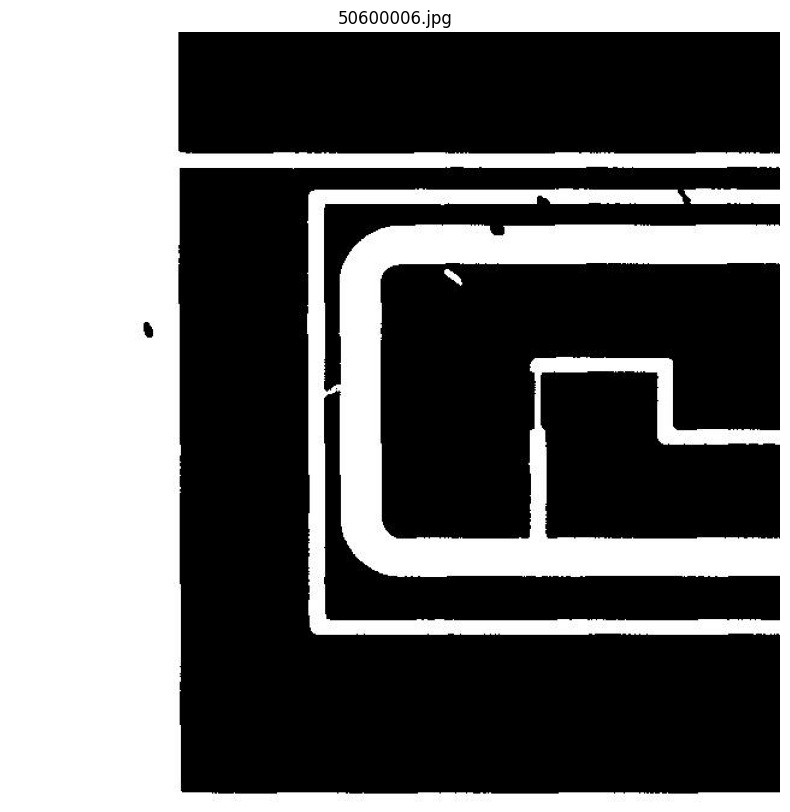

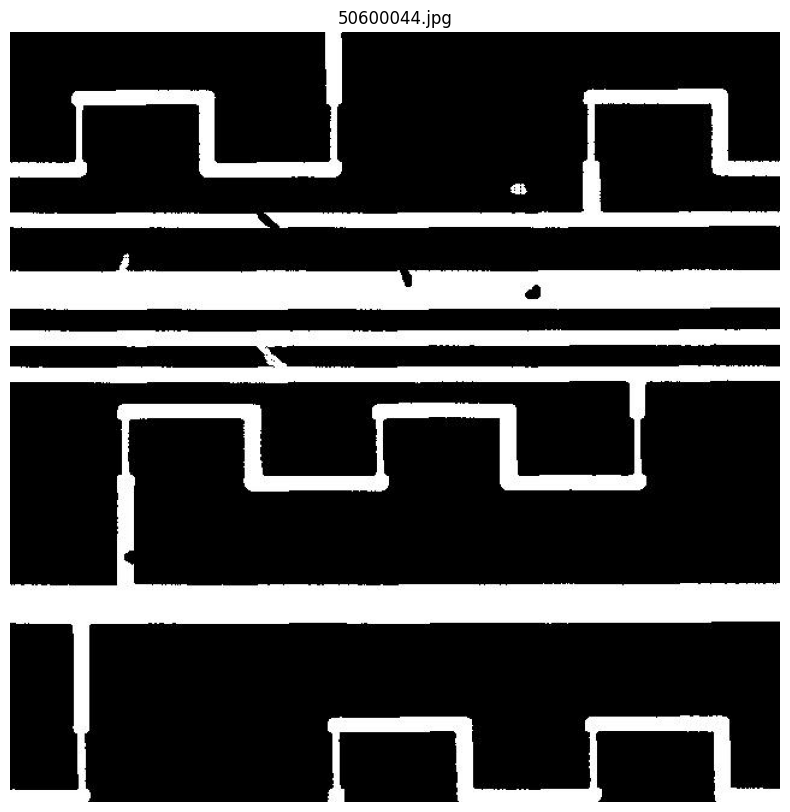

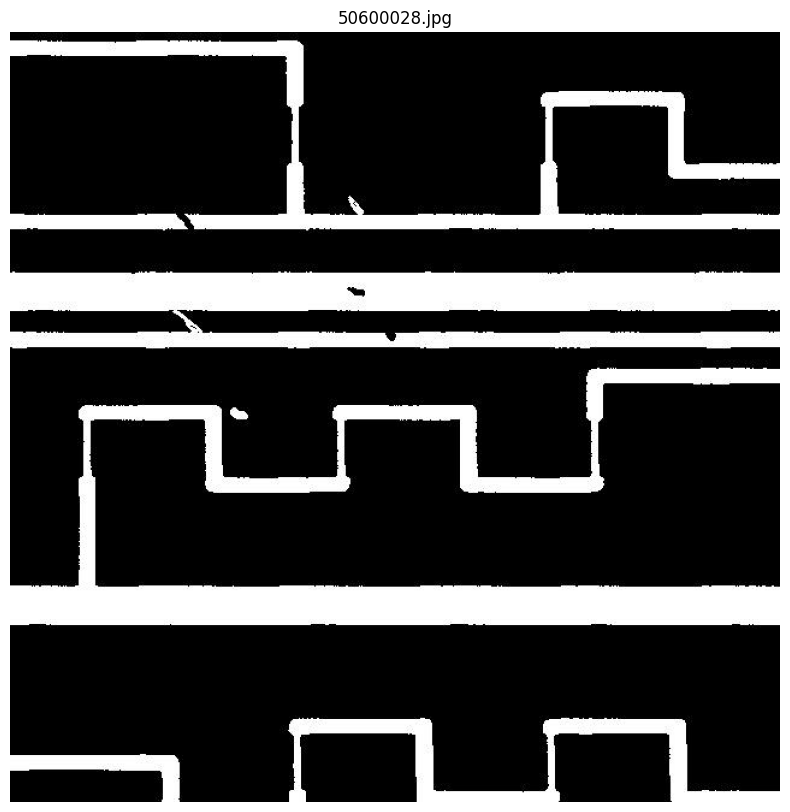

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

# 2. Define a function, plot_annotations
def plot_annotations(image_path, label_path, class_names):
    """Displays an image with its YOLO bounding box annotations overlaid."""
    # 3a. Load the image and convert to RGB
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: Could not load image {image_path}")
        return
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Get image dimensions
    h, w, _ = img.shape

    # 3c. Read the annotation file
    try:
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    class_id = int(parts[0])
                    center_x_norm, center_y_norm, bbox_width_norm, bbox_height_norm = map(float, parts[1:])

                    # 3d. Convert normalized coordinates to absolute pixel coordinates
                    x_center = int(center_x_norm * w)
                    y_center = int(center_y_norm * h)
                    box_w = int(bbox_width_norm * w)
                    box_h = int(bbox_height_norm * h)

                    x_min = int(x_center - box_w / 2)
                    y_min = int(y_center - box_h / 2)
                    x_max = int(x_center + box_w / 2)
                    y_max = int(y_center + box_h / 2)

                    # 3e. Draw the bounding box and add the class label
                    color = (0, 255, 0) # Green color for bounding box
                    cv2.rectangle(img, (x_min, y_min), (x_max, y_max), color, 2)

                    label = class_names[class_id] if class_id < len(class_names) else f'class_{class_id}'
                    font = cv2.FONT_HERSHEY_SIMPLEX
                    font_scale = 0.7
                    font_thickness = 2
                    text_size = cv2.getTextSize(label, font, font_scale, font_thickness)[0]
                    text_x = x_min
                    text_y = y_min - 10 if y_min - 10 > 10 else y_min + text_size[1] + 10 # Adjust text position
                    cv2.putText(img, label, (text_x, text_y), font, font_scale, color, font_thickness, cv2.LINE_AA)

    except FileNotFoundError:
        print(f"Error: Label file not found at {label_path}")
        return
    except Exception as e:
        print(f"Error processing annotations for {label_path}: {e}")
        return

    # 3f. Display the image with annotations
    plt.figure(figsize=(10, 10))
    plt.imshow(img)
    plt.title(os.path.basename(image_path))
    plt.axis('off')
    plt.show()

# 4. Select a few sample image and label file pairs from train_val_dataset_map
sample_count = 3
sample_base_names = list(train_val_dataset_map.keys())[:sample_count]

print(f"Displaying {sample_count} sample images with annotations from the training/validation set:")
for base_name in sample_base_names:
    image_original_path = train_val_dataset_map[base_name]['image']
    # Extract the extension from the original image path
    image_extension = os.path.splitext(image_original_path)[1]

    # Construct the path to the copied files in the YOLOv8 structure using the base_name
    # and the extracted extension for the image, and '.txt' for the label.
    yolov8_image_path = os.path.join(train_images_path, f"{base_name}{image_extension}")
    yolov8_label_path = os.path.join(train_labels_path, f"{base_name}.txt")

    plot_annotations(yolov8_image_path, yolov8_label_path, names)

## Train YOLOv8-Nano Model

### Subtask:
Initiate the training process for the YOLOv8-Nano model using the prepared dataset and configuration.


**Reasoning**:
The subtask requires initiating the training process for the YOLOv8-Nano model. This involves importing the YOLO class, loading the pre-trained 'yolov8n.pt' model, and then calling the train method with the specified configuration (data.yaml, epochs=50, imgsz=640, and project/name for organization).



In [ ]:
from ultralytics import YOLO

# 1. Load a pre-trained YOLOv8-nano model
model = YOLO('yolov8n.pt')

# 2. Train the model
# Specify data.yaml, epochs, imgsz, project, and name
results = model.train(
    data='data.yaml',
    epochs=50,
    imgsz=640,
    project='runs/detect',
    name='train_pcb_yolov8n'
)

print("YOLOv8-Nano model training initiated.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.11 🚀 Python-3.12.12 torch-2.9.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, ke

RuntimeError: No valid images found in /content/yolov8_dataset/train/labels.cache. Images with incorrectly formatted labels are ignored. See https://docs.ultralytics.com/datasets for dataset formatting guidance.

**Reasoning**:
The previous training step failed because the label files were either incorrectly formatted or contained non-normalized coordinates. The error messages indicated that the original label files might have absolute pixel coordinates and possibly multiple bounding box detections on a single line. To fix this, I need to modify the `copy_files_to_yolov8_structure` function to read the image dimensions, parse each line of the original label file by splitting it into 5-part chunks (assuming `class_id x_center_abs y_center_abs width_abs height_abs` for each bounding box), normalize these absolute pixel coordinates to the 0-1 range, and then write them into new label files in the standard YOLO format (one normalized bounding box per line).



In [ ]:
import os
import shutil
import cv2

# 1. Create the base directory for the YOLOv8 dataset structure
os.makedirs(yolov8_dataset_root, exist_ok=True)

# 2. Create the subdirectories within the yolov8_dataset_root
os.makedirs(train_images_path, exist_ok=True)
os.makedirs(train_labels_path, exist_ok=True)
os.makedirs(val_images_path, exist_ok=True)
os.makedirs(val_labels_path, exist_ok=True)
os.makedirs(test_images_path, exist_ok=True)
os.makedirs(test_labels_path, exist_ok=True)

print(f"Created YOLOv8 dataset directory structure under '{yolov8_dataset_root}'.")

# 3. Define a helper function, copy_files_to_yolov8_structure
def copy_files_to_yolov8_structure(dataset_map, image_dest_dir, label_dest_dir):
    """Copies image and label files to the YOLOv8-compatible directory structure,
    normalizing labels in the process. Assumes original labels are
    'class_id x_center_abs y_center_abs bbox_width_abs bbox_height_abs'
    (multiple detections might be on a single line, space-separated).
    """
    copied_count = 0
    converted_labels_count = 0
    for base_name, paths in dataset_map.items():
        if paths['image'] and paths['label']:
            try:
                # Determine new file names with .jpg and .txt extensions
                image_extension = os.path.splitext(paths['image'])[1]
                new_image_name = f"{base_name}{image_extension}"
                new_label_name = f"{base_name}.txt"

                # Define full paths for destination
                dest_image_path = os.path.join(image_dest_dir, new_image_name)
                dest_label_path = os.path.join(label_dest_dir, new_label_name)

                # Copy image file
                shutil.copy(paths['image'], dest_image_path)

                # Read image to get its dimensions for label normalization
                img = cv2.imread(paths['image'])
                if img is None:
                    print(f"Warning: Could not read image {paths['image']}. Skipping label conversion for this image.")
                    continue
                h, w, _ = img.shape

                # Convert and copy label file
                normalized_labels = []
                with open(paths['label'], 'r') as f_label:
                    for line_content in f_label:
                        parts = line_content.strip().split()
                        # Iterate through parts in chunks of 5 for each bounding box
                        for i in range(0, len(parts), 5):
                            if i + 4 < len(parts): # Ensure there are 5 parts for a bounding box
                                class_id = int(parts[i])
                                x_center_abs, y_center_abs, bbox_width_abs, bbox_height_abs = map(float, parts[i+1:i+5])

                                # Normalize coordinates
                                if w == 0 or h == 0:
                                    print(f"Warning: Image dimensions are zero for {paths['image']}. Skipping label normalization for this bounding box.")
                                    continue

                                x_center_norm = x_center_abs / w
                                y_center_norm = y_center_abs / h
                                bbox_width_norm = bbox_width_abs / w
                                bbox_height_norm = bbox_height_abs / h

                                # Ensure coordinates are within [0, 1] range
                                x_center_norm = max(0.0, min(1.0, x_center_norm))
                                y_center_norm = max(0.0, min(1.0, y_center_norm))
                                bbox_width_norm = max(0.0, min(1.0, bbox_width_norm))
                                bbox_height_norm = max(0.0, min(1.0, bbox_height_norm))

                                normalized_labels.append(
                                    f"{class_id} {x_center_norm:.6f} {y_center_norm:.6f} {bbox_width_norm:.6f} {bbox_height_norm:.6f}"
                                )
                            else:
                                print(f"Warning: Incomplete bounding box definition in line: '{line_content.strip()}' for {paths['label']}. Expected 5 parts per box, got {len(parts)-i} remaining. Skipping this incomplete box.")
                                # If an incomplete box is found, stop processing the current line to avoid errors
                                break

                if normalized_labels:
                    with open(dest_label_path, 'w') as f_out:
                        for nl in normalized_labels:
                            f_out.write(nl + '\n')
                    converted_labels_count += 1
                else:
                    # Create an empty label file if no valid labels were found to avoid YOLO error
                    print(f"Warning: No valid labels found or converted for {paths['label']}. Creating empty label file.")
                    open(dest_label_path, 'a').close()


                copied_count += 1
            except Exception as e:
                print(f"Error processing files for {base_name} (image: {paths['image']}, label: {paths['label']}): {e}")
    print(f"Successfully converted labels for {converted_labels_count} files.")
    return copied_count

# 4. Call the copy_files_to_yolov8_structure function
# For training/validation set
train_val_copied_count = copy_files_to_yolov8_structure(train_val_dataset_map, train_images_path, train_labels_path)

# For test set
test_copied_count = copy_files_to_yolov8_structure(test_dataset_map, test_images_path, test_labels_path)

# 5. Print a confirmation message
print(f"\n--- File Copy Summary ---")
print(f"Copied {train_val_copied_count} image/label pairs to training/validation directories.")
print(f"Copied {test_copied_count} image/label pairs to test directories.")

Created YOLOv8 dataset directory structure under 'yolov8_dataset'.
Successfully converted labels for 1000 files.
Successfully converted labels for 500 files.

--- File Copy Summary ---
Copied 1000 image/label pairs to training/validation directories.
Copied 500 image/label pairs to test directories.


**Reasoning**:
The previous step successfully converted the label files to the correct YOLOv8 format with normalized coordinates. Now, I will re-attempt to initiate the training process for the YOLOv8-Nano model using the prepared dataset and configuration, as outlined in the subtask.



In [ ]:
from ultralytics import YOLO

# 1. Load a pre-trained YOLOv8-nano model
model = YOLO('yolov8n.pt')

# 2. Train the model
# Specify data.yaml, epochs, imgsz, project, and name
results = model.train(
    data='data.yaml',
    epochs=50,
    imgsz=640,
    project='runs/detect',
    name='train_pcb_yolov8n'
)

print("YOLOv8-Nano model training initiated.")

Ultralytics 8.4.11 🚀 Python-3.12.12 torch-2.9.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_pcb_yolov8n2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, pl

FileNotFoundError: [34m[1mval: [0mError loading data from /content/yolov8_dataset/val/images
See https://docs.ultralytics.com/datasets for dataset formatting guidance.

**Reasoning**:
The previous training attempt failed because the validation image directory was empty. To fix this, I need to split the `train_val_dataset_map` into separate training and validation sets using `train_test_split` and then copy the files to their respective `yolov8_dataset/train` and `yolov8_dataset/val` directories. This ensures that the validation set is properly populated for the YOLOv8 model.



In [ ]:
import os
import shutil
import cv2
from sklearn.model_selection import train_test_split

# 1. Create the base directory for the YOLOv8 dataset structure
os.makedirs(yolov8_dataset_root, exist_ok=True)

# 2. Create the subdirectories within the yolov8_dataset_root
os.makedirs(train_images_path, exist_ok=True)
os.makedirs(train_labels_path, exist_ok=True)
os.makedirs(val_images_path, exist_ok=True)
os.makedirs(val_labels_path, exist_ok=True)
os.makedirs(test_images_path, exist_ok=True)
os.makedirs(test_labels_path, exist_ok=True)

print(f"Created YOLOv8 dataset directory structure under '{yolov8_dataset_root}'.")

# 3. Define a helper function, copy_files_to_yolov8_structure
def copy_files_to_yolov8_structure(dataset_map_split, image_dest_dir, label_dest_dir):
    """Copies image and label files to the YOLOv8-compatible directory structure,
    normalizing labels in the process. Assumes original labels are
    'class_id x_center_abs y_center_abs bbox_width_abs bbox_height_abs'
    (multiple detections might be on a single line, space-separated).
    """
    copied_count = 0
    converted_labels_count = 0
    for base_name, paths in dataset_map_split.items():
        if paths['image'] and paths['label']:
            try:
                # Determine new file names with .jpg and .txt extensions
                image_extension = os.path.splitext(paths['image'])[1]
                new_image_name = f"{base_name}{image_extension}"
                new_label_name = f"{base_name}.txt"

                # Define full paths for destination
                dest_image_path = os.path.join(image_dest_dir, new_image_name)
                dest_label_path = os.path.join(label_dest_dir, new_label_name)

                # Copy image file
                shutil.copy(paths['image'], dest_image_path)

                # Read image to get its dimensions for label normalization
                img = cv2.imread(paths['image'])
                if img is None:
                    print(f"Warning: Could not read image {paths['image']}. Skipping label conversion for this image.")
                    continue
                h, w, _ = img.shape

                # Convert and copy label file
                normalized_labels = []
                with open(paths['label'], 'r') as f_label:
                    for line_content in f_label:
                        parts = line_content.strip().split()
                        # Iterate through parts in chunks of 5 for each bounding box
                        for i in range(0, len(parts), 5):
                            if i + 4 < len(parts): # Ensure there are 5 parts for a bounding box
                                class_id = int(parts[i])
                                x_center_abs, y_center_abs, bbox_width_abs, bbox_height_abs = map(float, parts[i+1:i+5])

                                # Normalize coordinates
                                if w == 0 or h == 0:
                                    print(f"Warning: Image dimensions are zero for {paths['image']}. Skipping label normalization for this bounding box.")
                                    continue

                                x_center_norm = x_center_abs / w
                                y_center_norm = y_center_abs / h
                                bbox_width_norm = bbox_width_abs / w
                                bbox_height_norm = bbox_height_abs / h

                                # Ensure coordinates are within [0, 1] range
                                x_center_norm = max(0.0, min(1.0, x_center_norm))
                                y_center_norm = max(0.0, min(1.0, y_center_norm))
                                bbox_width_norm = max(0.0, min(1.0, bbox_width_norm))
                                bbox_height_norm = max(0.0, min(1.0, bbox_height_norm))

                                normalized_labels.append(
                                    f"{class_id} {x_center_norm:.6f} {y_center_norm:.6f} {bbox_width_norm:.6f} {bbox_height_norm:.6f}"
                                )
                            else:
                                print(f"Warning: Incomplete bounding box definition in line: '{line_content.strip()}' for {paths['label']}. Expected 5 parts per box, got {len(parts)-i} remaining. Skipping this incomplete box.")
                                # If an incomplete box is found, stop processing the current line to avoid errors
                                break

                if normalized_labels:
                    with open(dest_label_path, 'w') as f_out:
                        for nl in normalized_labels:
                            f_out.write(nl + '\n')
                    converted_labels_count += 1
                else:
                    # Create an empty label file if no valid labels were found to avoid YOLO error
                    print(f"Warning: No valid labels found or converted for {paths['label']}. Creating empty label file.")
                    open(dest_label_path, 'a').close()


                copied_count += 1
            except Exception as e:
                print(f"Error processing files for {base_name} (image: {paths['image']}, label: {paths['label']}): {e}")
    print(f"Successfully converted labels for {converted_labels_count} files.")
    return copied_count

# --- New part: Split train_val_dataset_map into actual train and val ---
# Convert the dictionary keys to a list to use with train_test_split
train_val_base_names_list = list(train_val_dataset_map.keys())

# Split into training and validation sets (e.g., 80% train, 20% val)
train_split_names, val_split_names = train_test_split(
    train_val_base_names_list, test_size=0.2, random_state=42
)

# Create new dictionaries for the actual train and validation data
train_actual_dataset_map = {name: train_val_dataset_map[name] for name in train_split_names}
val_actual_dataset_map = {name: train_val_dataset_map[name] for name in val_split_names}

print(f"Split training/validation set into {len(train_actual_dataset_map)} training samples and {len(val_actual_dataset_map)} validation samples.")


# 4. Call the copy_files_to_yolov8_structure function for each split
# For actual training set
train_copied_count = copy_files_to_yolov8_structure(train_actual_dataset_map, train_images_path, train_labels_path)

# For actual validation set
val_copied_count = copy_files_to_yolov8_structure(val_actual_dataset_map, val_images_path, val_labels_path)

# For test set (this remains the same)
test_copied_count = copy_files_to_yolov8_structure(test_dataset_map, test_images_path, test_labels_path)

# 5. Print a confirmation message
print(f"\n--- File Copy Summary ---")
print(f"Copied {train_copied_count} image/label pairs to training directories.")
print(f"Copied {val_copied_count} image/label pairs to validation directories.")
print(f"Copied {test_copied_count} image/label pairs to test directories.")

Created YOLOv8 dataset directory structure under 'yolov8_dataset'.
Split training/validation set into 800 training samples and 200 validation samples.
Successfully converted labels for 800 files.
Successfully converted labels for 200 files.
Successfully converted labels for 500 files.

--- File Copy Summary ---
Copied 800 image/label pairs to training directories.
Copied 200 image/label pairs to validation directories.
Copied 500 image/label pairs to test directories.


**Reasoning**:
The training dataset and validation dataset folders have now been correctly populated. I will re-run the training process with the corrected data structure. It is important to note that I will change the name of the training run slightly to avoid conflicts from previous failed attempts and ensure a fresh start for the model training.



In [20]:
from ultralytics import YOLO

# 1. Load a pre-trained YOLOv8-nano model
model = YOLO('yolov8n.pt')

# 2. Train the model
# Specify data.yaml, epochs, imgsz, project, and name
results = model.train(
    data='data.yaml',
    epochs=50,
    imgsz=640,
    project='runs/detect',
    name='train_pcb_yolov8n_v2' # Changed name to avoid conflict and signify a fresh attempt
)

print("YOLOv8-Nano model training initiated.")

Ultralytics 8.4.11 🚀 Python-3.12.12 torch-2.9.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_pcb_yolov8n_v22, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0,

KeyboardInterrupt: 